# Kapitza potential
We search when $U_{\textrm{eff}}$ is important or not in the expression of Keldysh model. 

In [4]:
import octopus_slabs
import spp_extended_theory
import os
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
sppextendedtheory=os.environ["spp_extended_theory"]
print(OctopusData, OctopusSources, sppextendedtheory)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs /home/thibault.derrien/Documents/spp-extended-theory


In [6]:
from spp_extended_theory.Keldysh.libKeldysh import DawsonIntegral

In [7]:
import matplotlib.pyplot as plt
import numpy as np

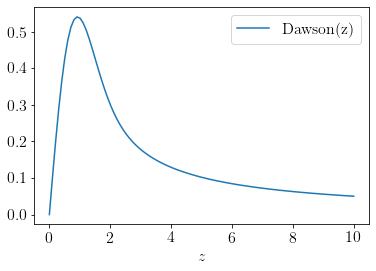

In [16]:
plt.figure()
z=np.linspace(0,10,100)
result=DawsonIntegral(z)
plt.plot(z, result, label="Dawson(z)")
plt.xlabel(r"$z$")
plt.legend(loc="best")
plt.show()

The Dawson integral is then limited to unity, but is summer $n$ times. 

The term is also multiplied by an exponential term that should be checked. 

In [37]:
from spp_extended_theory.Keldysh.libKeldysh import *
# Egap=2.56*e; meff=1;PeakField=1E9; 
# gamma = gammaKeldysh(Egap, meff, PeakField, wavelength, RefractiveIndex.real) #valid for scalar data
Egap=2.56*e; omegaLaser=2*np.pi*c/800e-9
gammaLog = np.linspace(-2,1,500)
gamma = np.power(10.,gammaLog)
k1 = Keldysh1phi(gamma); k2 = Keldysh2theta(gamma) #valid
Ueff = EffectiveGap(Egap, k1, k2) # Original formula from Keldysh. Warning: scipy.special.ellipe (https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.ellipe.html#scipy.special.ellipe) uses a different convention than Maple, Wikipedia or mpmath.
# KeldyshFunctionResultG = KeldyshFunction_Gruzdev( k1, k2, EgapEff, order, wavelength )
Keldysh1phi2 = np.float64(k1 * k1)
Keldysh2theta2 = np.float64(k2 * k2)
ExternalExp = np.exp(-pi*np.trunc(Ueff/hbar/omegaLaser+1e0)*((ellipk(Keldysh1phi2)-ellipe(Keldysh1phi2))/(ellipe(Keldysh2theta2))))

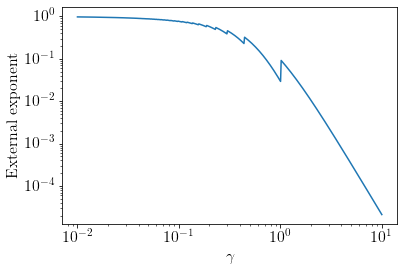

In [40]:
plt.figure()
plt.loglog(gamma,ExternalExp)
plt.xlabel(r"$\gamma$")
plt.ylabel("External exponent")
plt.show()

## Estimation of the Dawson integral term

Warning: in this part, it is not possible to consider $gamma$ as an array (yet). 

In [72]:
gamma = 1E3
k1 = Keldysh1phi(gamma); k2 = Keldysh2theta(gamma) #valid
Ueff = EffectiveGap(Egap, k1, k2)
n=np.arange(0,500)
Keldysh1phi2_128 = k1**2
Keldysh1phi2 = np.float64(Keldysh1phi2_128)
Keldysh2theta2 = np.float64(k2**2)
# print "Keldysh1phi2 = "+str(Keldysh1phi2)
distant_to_unity = 1E0 - Keldysh1phi2_128
if (distant_to_unity.any() < 1E-320): #then it gonna crash for sure. 
    print("** Error on ellipk: a rgument 1 is singular. Distance to unit = "+str(distant_to_unity)+"Please increase precision on Keldysh1phi or use ellipkm1 function (careful, argument IS not the same).")
elif(distant_to_unity.any() < 1E-10):
  #threshol d where functions ellipk and ellipkm1 give different values
    EllipticK1_phi = ellipkm1( np.float64(distant_to_unity) )
else: #other cases, good for efficiency
    EllipticK1_phi = ellipk( Keldysh1phi2 ) #inf if Keldysh1phi2 = 1.i
EllipticE1_phi   = ellipe( Keldysh1phi2 )  
EllipticE2_theta = ellipe( Keldysh2theta2 ) 

DawsonIntTerms = DawsonIntegral(np.pi*np.sqrt( ((np.trunc(Ueff/hbar/omegaLaser+1.))-Ueff/hbar/omegaLaser + n) / (2.0 * ellipk(Keldysh2theta2)*EllipticE2_theta) ) )

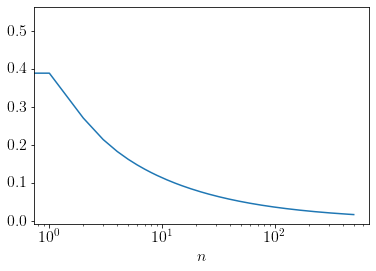

In [73]:
plt.figure()
plt.semilogx(n,DawsonIntTerms)
plt.xlabel(r"$n$")
plt.show()